<a href="https://colab.research.google.com/github/RashiBista/TUMORR/blob/main/01_dataser_exploration_and_quality_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
DATA_DIR = Path(
    "/content/drive/MyDrive/Dataset"
)
print("Dataset exists:", DATA_DIR.exists())
print("\nFiles inside Dataset")

for item in DATA_DIR.iterdir():
  print(item.name)

Dataset exists: True

Files inside Dataset
braintumor.zip
extract


In [35]:
import zipfile
zip_file = list(DATA_DIR.glob(" *.zip"))
print("Zip file found: ")

for file in zip_file:
  print(file.name)


Zip file found: 


In [36]:
# Search correctly without a leading space
zip_files = list(DATA_DIR.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError("No .zip files found in " + str(DATA_DIR))

# Take the first found zip file
ZIP_PATH = zip_files[0]

EXTRACT_DIR = DATA_DIR / "extract"
EXTRACT_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
  zip_ref.extractall(EXTRACT_DIR)

print("Extraction completed to:", EXTRACT_DIR)

KeyboardInterrupt: 

In [37]:
for path in sorted(EXTRACT_DIR.glob("*")):

  if path.is_dir():
    print("folder", path.relative_to(EXTRACT_DIR))
  else:
    print("file", path.relative_to(EXTRACT_DIR))

folder Brain Tumor CT scan Images
folder Brain Tumor MRI images
folder Dataset


In [38]:
from pathlib import Path

EXTRACT_DIR = Path(
    "/content/drive/MyDrive/Dataset/extract"
)

print("Path:", EXTRACT_DIR)
print("Exists:", EXTRACT_DIR.exists())

if EXTRACT_DIR.exists():
    print("\nContents:")

    for item in EXTRACT_DIR.iterdir():
        print(
            "📁" if item.is_dir() else "📄",
            item.name
        )

Path: /content/drive/MyDrive/Dataset/extract
Exists: True

Contents:
📁 Brain Tumor CT scan Images
📁 Brain Tumor MRI images
📁 Dataset


In [39]:
for path in sorted(EXTRACT_DIR.glob("*")):
  if path.is_dir() and path.name.lower() in ["healthy" , "tumor"]:
    print(path)

In [40]:
class_folders = []

for path in EXTRACT_DIR.rglob("*"):

    if path.is_dir():

        if path.name.strip().lower() in ["healthy", "tumor"]:

            class_folders.append(path)

print("Class folders found:", len(class_folders))

for folder in class_folders:
    print(folder)

Class folders found: 5
/content/drive/MyDrive/Dataset/extract/Brain Tumor CT scan Images/Healthy
/content/drive/MyDrive/Dataset/extract/Brain Tumor CT scan Images/Tumor
/content/drive/MyDrive/Dataset/extract/Brain Tumor MRI images/Healthy
/content/drive/MyDrive/Dataset/extract/Brain Tumor MRI images/Tumor
/content/drive/MyDrive/Dataset/extract/Dataset/Brain Tumor CT scan Images/Healthy


In [41]:
from collections import defaultdict

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff"
}

dataset_counts = defaultdict(int)

for path in EXTRACT_DIR.rglob("*"):

    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:

        parts = path.relative_to(EXTRACT_DIR).parts

        modality = parts[0]
        category = next(
            (p for p in parts if p.lower() in ["healthy", "tumor"]),
            "Unknown"
        )

        dataset_counts[(modality, category)] += 1

for (modality, category), count in sorted(dataset_counts.items()):
    print(f"{modality} | {category}: {count}")

Brain Tumor CT scan Images | Healthy: 2300
Brain Tumor CT scan Images | Tumor: 2318
Brain Tumor MRI images | Healthy: 2000
Brain Tumor MRI images | Tumor: 3000
Dataset | Healthy: 601


#Visualization

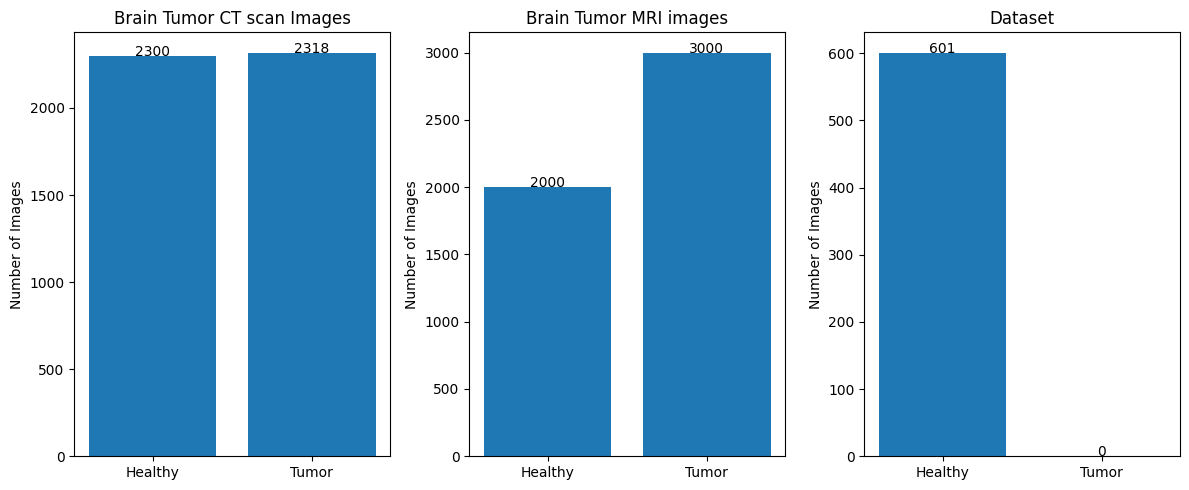

In [42]:
import matplotlib.pyplot as plt

modalities = sorted(set(m for m, c in dataset_counts))

fig, axes = plt.subplots(
    1, len(modalities),
    figsize=(12, 5)
)

if len(modalities) == 1:
    axes = [axes]

for ax, modality in zip(axes, modalities):

    categories = ["Healthy", "Tumor"]

    values = [
        dataset_counts[(modality, category)]
        for category in categories
    ]

    ax.bar(categories, values)
    ax.set_title(modality)
    ax.set_ylabel("Number of Images")

    for i, value in enumerate(values):
        ax.text(i, value, str(value), ha="center")

plt.tight_layout()
plt.show()

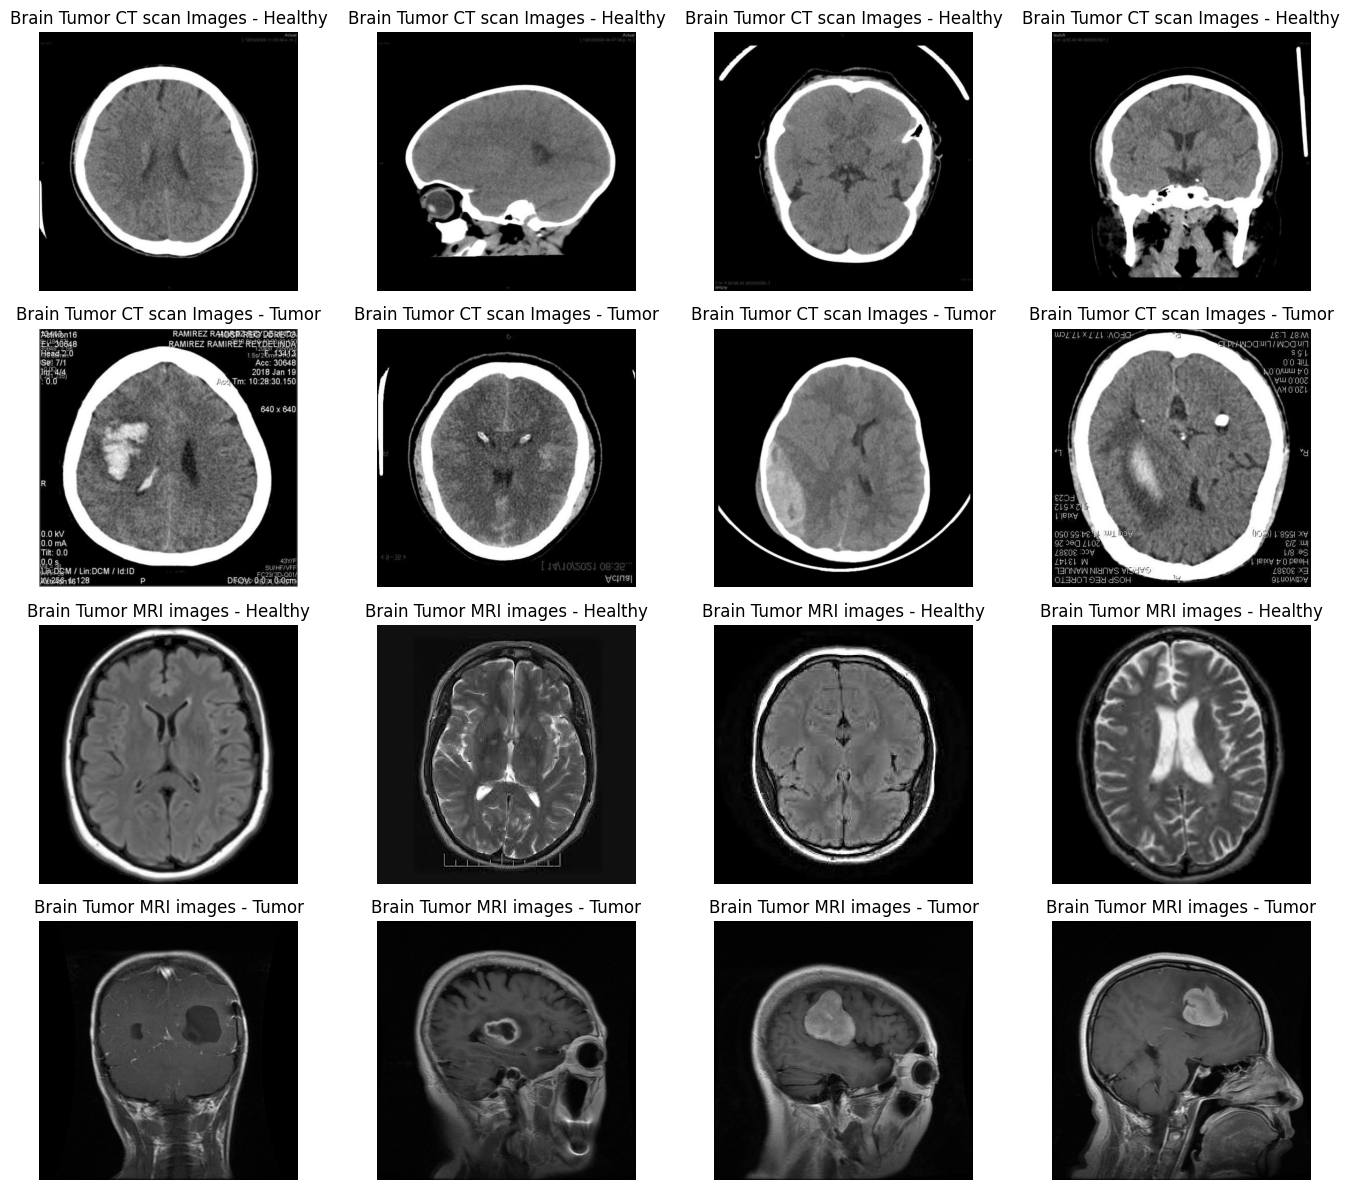

In [43]:
from PIL import Image
import matplotlib.pyplot as plt
import random

random.seed(42)

class_dirs = {}

for path in EXTRACT_DIR.rglob("*"):

    if path.is_dir() and path.name.lower() in ["healthy", "tumor"]:

        modality = next(
            (p.name for p in path.parents
             if "ct" in p.name.lower() or "mri" in p.name.lower()),
            "Unknown"
        )

        class_dirs[(modality, path.name)] = path

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for row, (key, folder) in enumerate(sorted(class_dirs.items())):

    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    samples = random.sample(images, min(4, len(images)))

    for col, image_path in enumerate(samples):

        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{key[0]} - {key[1]}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Metadata Extraction

In [44]:
from pathlib import Path
from PIL import Image
import pandas as pd

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff"
}

image_records = []
corrupted_images = []

for path in EXTRACT_DIR.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    relative_parts = path.relative_to(EXTRACT_DIR).parts

    # Identify modality and class
    modality = relative_parts[0]
    label = path.parent.name

    try:
        with Image.open(path) as img:

            image_records.append({
                "path": str(path),
                "modality": modality,
                "label": label,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "format": img.format,
                "file_size_kb": round(
                    path.stat().st_size / 1024, 2
                )
            })

    except Exception as e:
        corrupted_images.append({
            "path": str(path),
            "error": str(e)
        })

df = pd.DataFrame(image_records)

print("Successfully inspected:", len(df))
print("Unreadable images:", len(corrupted_images))
print("\nFirst five records:")

display(df.head())

Successfully inspected: 10218
Unreadable images: 1

First five records:


,path,modality,label,width,height,mode,format,file_size_kb
0,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy,205,255,L,JPEG,7.39
1,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy,352,511,RGB,PNG,96.60
2,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy,225,225,RGB,JPEG,8.72
3,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy,230,315,RGB,PNG,69.26
4,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy,512,512,RGB,JPEG,84.42


In [45]:
print("Most common image dimenssions: \n")

display(
    df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(20)
)

Most common image dimenssions: 



,,0
width,height,
640,640,4169
512,512,3350
256,256,570
225,225,198
630,630,124
236,236,86
224,224,77
442,442,56
300,168,43


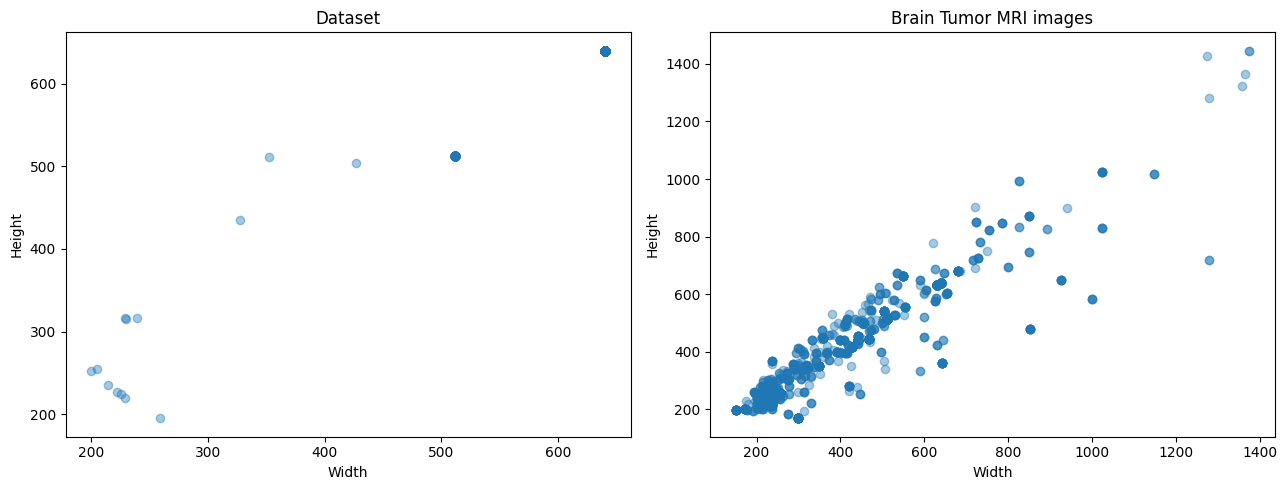

In [46]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13,5))

for ax, modality in zip(axes,df["modality"].unique()):
  subset = df[df["modality"] == modality]
  ax.scatter(
      subset["width"],
      subset["height"],
      alpha=0.4
  )
  ax.set_title(modality)
  ax.set_xlabel("Width")
  ax.set_ylabel("Height")

plt.tight_layout()
plt.show()




In [47]:
print("Image modes by modality:")

display(
    pd.crosstab(
        df["modality"],
        df["mode"]
    )
)

print("\nImage formats by modality:")

display(
    pd.crosstab(
        df["modality"],
        df["format"]
    )
)

Image modes by modality:


mode,L,RGB,RGBA
modality,,,
Brain Tumor CT scan Images,561,4045,12
Brain Tumor MRI images,285,4712,3
Dataset,49,550,1



Image formats by modality:


format,JPEG,PNG
modality,,
Brain Tumor CT scan Images,3873,745
Brain Tumor MRI images,4997,3
Dataset,545,55


In [48]:
print("Total unreadable images: ",len(corrupted_images))
if corrupted_images:
  for item in corrupted_images:
    print(item["path"],item["error"])
else:
  print("No corrupted images found")

Total unreadable images:  1
/content/drive/MyDrive/Dataset/extract/Dataset/Brain Tumor CT scan Images/Healthy/ct_healthy (149).jpg cannot identify image file '/content/drive/MyDrive/Dataset/extract/Dataset/Brain Tumor CT scan Images/Healthy/ct_healthy (149).jpg'


## Deleting corrupted

In [49]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for path in df["path"]:

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(lambda: f.read(8192), b""):
            sha256.update(chunk)

    hash_groups[sha256.hexdigest()].append(path)

duplicates = {
    h: paths
    for h, paths in hash_groups.items()
    if len(paths) > 1
}

print("Unique image contents:", len(hash_groups))
print("Duplicate groups:", len(duplicates))

duplicate_count = sum(
    len(paths) - 1
    for paths in duplicates.values()
)

print("Extra duplicate copies:", duplicate_count)

for paths in list(duplicates.values())[:10]:

    print("\nDuplicate group:")

    for path in paths:
        print(path)

Unique image contents: 9106
Duplicate groups: 977
Extra duplicate copies: 1112

Duplicate group:
/content/drive/MyDrive/Dataset/extract/Dataset/Brain Tumor CT scan Images/Healthy/ct_healthy (1).jpg
/content/drive/MyDrive/Dataset/extract/Brain Tumor CT scan Images/Healthy/ct_healthy (1).jpg

Duplicate group:
/content/drive/MyDrive/Dataset/extract/Dataset/Brain Tumor CT scan Images/Healthy/ct_healthy (1).png
/content/drive/MyDrive/Dataset/extract/Brain Tumor CT scan Images/Healthy/ct_healthy (1).png

Duplicate group:
/content/drive/MyDrive/Dataset/extract/Dataset/Brain Tumor CT scan Images/Healthy/ct_healthy (10).jpg
/content/drive/MyDrive/Dataset/extract/Brain Tumor CT scan Images/Healthy/ct_healthy (10).jpg

Duplicate group:
/content/drive/MyDrive/Dataset/extract/Dataset/Brain Tumor CT scan Images/Healthy/ct_healthy (10).png
/content/drive/MyDrive/Dataset/extract/Brain Tumor CT scan Images/Healthy/ct_healthy (10).png

Duplicate group:
/content/drive/MyDrive/Dataset/extract/Dataset/Brai

In [50]:
for paths in duplicates.values():

    metadata = df[df["path"].isin(paths)]

    if (
        metadata["label"].nunique() > 1
        or metadata["modality"].nunique() > 1
    ):

        print("\nPotential cross-class/modality leakage:")

        display(
            metadata[["path", "modality", "label"]]
        )


Potential cross-class/modality leakage:


,path,modality,label
0,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy
5600,/content/drive/MyDrive/Dataset/extract/Brain T...,Brain Tumor CT scan Images,Healthy



Potential cross-class/modality leakage:


,path,modality,label
1,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy
5601,/content/drive/MyDrive/Dataset/extract/Brain T...,Brain Tumor CT scan Images,Healthy



Potential cross-class/modality leakage:


,path,modality,label
2,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy
5602,/content/drive/MyDrive/Dataset/extract/Brain T...,Brain Tumor CT scan Images,Healthy


... (1,190 outputs left out)


Potential cross-class/modality leakage:


,path,modality,label
598,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy
6198,/content/drive/MyDrive/Dataset/extract/Brain T...,Brain Tumor CT scan Images,Healthy



Potential cross-class/modality leakage:


,path,modality,label
599,/content/drive/MyDrive/Dataset/extract/Dataset...,Dataset,Healthy
6199,/content/drive/MyDrive/Dataset/extract/Brain T...,Brain Tumor CT scan Images,Healthy
